# RoadSense v1: zero-shot baseline and first fine-tuning

Road segmentation on Beninese roads (Cotonou, Abomey-Calavi)
Do road segmentation models trained on European streets work on West African roads, and when they fail, is it a problem of **appearance** (the surface looks unfamiliar) or of **definition** (the model sees the surface but does not call it a road)?

This notebook has four parts:

1. **Zero-shot baseline**: SegFormer-B0 and B2 trained on Cityscapes (European streets), evaluated as-is on the RoadSense test set. Road IoU per surface type, and where the missed road pixels go (class-wise confusion).

2. **First fine-tuning**: SegFormer-B0 retrained on the 59 images of the RoadSense `train` split (binary road / background), evaluated on the same test set.

3. **Pre-annotation**: the fine-tuned model draws road polygons on the `preannotate` split, exported as CVAT XML for manual correction.

4. **Asphalt, dry vs rain**: a closer look at asphalt, the surface closest to Cityscapes.

**Data.** 63 test images and 59 training images extracted from phone videos (1 frame per second), annotated by hand in CVAT with a single `road` label. The dataset is not public yet (faces and licence plates are not anonymised); outputs are kept in the notebook so results can be read without running it.

It took about 9 minutes to fine-turne it on Kaggle GPU T4 with the `roadsense-v0` dataset attached.


In [26]:
# Imports

import os
import glob
import json 
import random
import time
from pathlib import Path


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import torch
import torch.nn.functional as F
from transformers import SegformerForSemanticSegmentation

In [3]:
# Path of the dataset folder (the one that contains index.csv)

INDEX_FILE = "/kaggle/input/datasets/freudbokossa/roadsense-v0/dataset/index.csv"

DATA = "/kaggle/input/datasets/freudbokossa/roadsense-v0/dataset"
OUT = '/kaggle/working' 

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print('data:', DATA)
print('device:', DEVICE)



data: /kaggle/input/datasets/freudbokossa/roadsense-v0/dataset
device: cuda


One test image is almost entirely occluded (the road is barely visible behind the driver). It is flagged with `exclude_from_eval = 1` and left out, which leaves **63 test images**.

In [4]:
index = pd.read_csv(INDEX_FILE, dtype={'id': str})
print(index.groupby('split').size())
test = index[(index.split == 'test') & (index.exclude_from_eval == 0)].reset_index(drop=True)
train = index[index.split == 'train'].reset_index(drop=True)
print()
print('Test images:', len(test), ' - Train images:', len(train))
print(test.surface.value_counts())

split
preannotate    112
test            64
train           59
dtype: int64

Test images: 63  - Train images: 59
surface
unpaved                23
asphalt                21
sand_covered_pavers    10
pavers                  8
mixed                   1
Name: count, dtype: int64


In [5]:
index.head()

,id,split,file,mask,source_file,video,time_s,surface,lighting,weather,note,exclude_from_eval,road_fraction,cvat_task
0,0001,test,test/images/0001.jpg,test/masks/0001.png,20260930_074322_f000026.jpg,20260930_074322.mp4,1.0,pavers,day,dry,passenger_view,0,0.389,main
1,0002,test,test/images/0002.jpg,test/masks/0002.png,20260930_074322_f000078.jpg,20260930_074322.mp4,3.0,pavers,day,dry,passenger_view,0,0.312,main
2,0003,test,test/images/0003.jpg,test/masks/0003.png,20260930_074322_f000156.jpg,20260930_074322.mp4,6.0,pavers,day,dry,passenger_view,0,0.238,main
3,0004,test,test/images/0004.jpg,test/masks/0004.png,20260930_074322_f000208.jpg,20260930_074322.mp4,8.0,pavers,day,dry,passenger_view,0,0.259,main
4,0005,test,test/images/0005.jpg,test/masks/0005.png,20260930_074322_f000286.jpg,20260930_074322.mp4,11.0,pavers,day,dry,passenger_view,0,0.317,main


## Shared helpers

Images are 1080 x 1920 (portrait). The network sees a resized copy; predictions are resized back to full resolution before scoring, so every score is computed on the original masks.

In [7]:
MEAN = np.array([0.485, 0.456, 0.406]) * 255
STD = np.array([0.229, 0.224, 0.225]) * 255

def load_image(row):
    img = cv2.imread(Path(DATA) / row['file'])
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

def load_mask(row):
    return cv2.imread(Path(DATA) / row['mask'], cv2.IMREAD_GRAYSCALE)

def to_tensor(img_rgb, size):  # size = (height, width)
    x = cv2.resize(img_rgb, (size[1], size[0]), interpolation=cv2.INTER_LINEAR)
    x = (x - MEAN) / STD
    return torch.from_numpy(x.transpose(2, 0, 1)).float()

@torch.no_grad()
def predict_logits(model, img_rgb, size):
    
    x = to_tensor(img_rgb, size).unsqueeze(0).to(DEVICE)
    with torch.autocast(device_type='cuda', enabled= DEVICE == 'cuda'):
        
        logits = model(pixel_values=x).logits          # (1, C, h/4, w/4)
    logits = F.interpolate(logits.float(), size=img_rgb.shape[:2], mode='bilinear', align_corners=False)
    return logits[0]                                     # (C, H, W) at full resolution

def iou_counts(pred, gt):
    inter = np.logical_and(pred == 1, gt == 1).sum()
    union = np.logical_or(pred == 1, gt == 1).sum()
    return inter, union

def summarize(per_image, name):
    # Pooled IoU 
    df = pd.DataFrame(per_image)
    g = df.groupby('surface')[['inter', 'union']].sum()
    g['road_iou'] = g.inter / g.union
    g['n_images'] = df.groupby('surface').size()
    overall = df.inter.sum() / df.union.sum()
    g.loc['ALL'] = [df.inter.sum(), df.union.sum(), overall, len(df)]
    g['n_images'] = g['n_images'].astype(int)
    g = g[['n_images', 'road_iou']].round(3)
    g.columns = ['n_images', name]
    return g, df

## 1. Zero-shot baseline (Cityscapes models, no RoadSense training)

Cityscapes has 19 classes. A pixel counts as road when the model predicts the class `road`. For every ground-truth road pixel that the model misses, we record which class it predicted instead. This tells us whether a failure looks like a **definition** problem (road seen as `sidewalk` or `terrain`: the model sees a flat ground surface but does not call it road) or an **appearance** problem (road seen as something unrelated, such as `vegetation` or `building`).

Scores are **pooled IoU**: intersections and unions are summed over all images of a group before dividing, so images with a large road area weigh more.

Inference size 1536 x 864 keeps the portrait aspect ratio and a road scale close to Cityscapes.

In [8]:
# Zero-shot evaluation helpers
ZS_MODELS = ['nvidia/segformer-b0-finetuned-cityscapes-1024-1024',
             'nvidia/segformer-b2-finetuned-cityscapes-1024-1024']
ZS_SIZE = (1536, 864)

def check_one_image(model, road_id, r):
  
    img = load_image(r)
    gt = load_mask(r)                                               
    cls = predict_logits(model, img, ZS_SIZE).argmax(0).cpu().numpy() 
    pred = (cls == road_id).astype(np.uint8)                           
    inter, union = iou_counts(pred, gt)
    lost = cls[(gt == 1) & (pred == 0)]       
    return inter, union, lost

def test_model(name):
    
    model = SegformerForSemanticSegmentation.from_pretrained(name).to(DEVICE).eval()
    labels = [model.config.id2label[i] for i in range(model.config.num_labels)]   
    road_id = labels.index('road')                                               

    rows = []
    for _, r in test.iterrows():
        inter, union, lost = check_one_image(model, road_id, r)
        rows.append({'id': r['id'], 'surface': r['surface'], 'weather': r['weather'],
                     'inter': inter, 'union': union,
                     'missed': np.bincount(lost, minlength=len(labels))})   

    del model; torch.cuda.empty_cache()           
    return pd.DataFrame(rows), labels


In [9]:
# Run both zero-shot models on the test set

res_b0, labels = test_model(ZS_MODELS[0])
res_b2, _      = test_model(ZS_MODELS[1])

res_b0.head()


config.json:   0%|          | 0.00/1.68k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 15.0MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 14.9MB            

...

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/380 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  109MB            

model.safetensors: downloading bytes:           |  0.00B            

,id,surface,weather,inter,union,missed
0,0001,pavers,dry,779107,847919,"[0, 17321, 0, 0, 0, 324, 0, 0, 291, 97, 458, 3..."
1,0002,pavers,dry,635709,730229,"[0, 2313, 224, 0, 0, 623, 0, 0, 40, 0, 267, 28..."
2,0003,pavers,dry,477254,552348,"[0, 2008, 30, 0, 0, 0, 0, 0, 0, 0, 0, 3557, 55..."
3,0004,pavers,dry,522477,550677,"[0, 310, 496, 0, 0, 589, 0, 0, 0, 0, 68, 4183,..."
4,0005,pavers,dry,649023,667419,"[0, 2672, 0, 0, 0, 0, 0, 0, 0, 0, 0, 733, 129,..."


In [10]:
table_b0, _ = summarize(res_b0, 'zero_shot_b0')
table_b2, _ = summarize(res_b2, 'zero_shot_b2')

zero_shot = pd.concat([table_b0, table_b2], axis=1)    
zero_shot.to_csv(f'{OUT}/zero_shot_road_iou.csv')
zero_shot


,n_images,zero_shot_b0,n_images,zero_shot_b2
surface,,,,
asphalt,21,0.847,21,0.868
mixed,1,0.990,1,0.988
pavers,8,0.884,8,0.844
sand_covered_pavers,10,0.966,10,0.971
unpaved,23,0.816,23,0.847
ALL,63,0.863,63,0.880


**Observations.** Zero-shot, both models stay above 0.84 on every surface with several images. Unpaved roads are the hardest (0.816 for B0, 0.847 for B2). Sand-covered pavers are the easiest (about 0.97), contrary to what we expected. B2 is better than B0 overall, except on pavers.

In [11]:
# Where do the missed road pixels go
def missed_percent(res):
    
    conf = pd.DataFrame(list(res.missed), columns=labels)   
    conf['surface'] = res.surface                           
    conf = conf.groupby('surface').sum()                   
    return (conf.div(conf.sum(axis=1), axis=0) * 100).round(1)   # in %

conf_b2 = missed_percent(res_b2)
conf_b2


,road,sidewalk,building,wall,fence,pole,traffic light,traffic sign,vegetation,terrain,sky,person,rider,car,truck,bus,train,motorcycle,bicycle
surface,,,,,,,,,,,,,,,,,,,
asphalt,0.0,38.2,6.3,0.2,0.0,0.2,0.0,1.8,0.6,3.9,0.0,20.9,6.9,14.3,0.1,0.8,0.0,2.7,3.0
mixed,0.0,81.4,0.0,0.0,0.0,0.0,0.0,0.0,6.5,2.6,0.0,1.1,0.0,0.0,0.0,0.0,0.0,0.0,8.4
pavers,0.0,19.1,18.2,0.0,0.0,1.3,0.0,0.0,0.1,0.0,2.2,17.6,6.8,22.7,0.1,2.6,0.0,2.0,7.1
sand_covered_pavers,0.0,15.3,0.0,0.0,0.0,0.2,0.0,0.6,72.6,0.1,0.0,1.6,3.5,2.6,0.0,0.0,0.0,1.6,1.8
unpaved,0.0,58.7,3.1,13.0,0.2,0.3,0.0,0.0,19.1,3.5,0.0,0.4,0.1,0.7,0.1,0.0,0.0,0.4,0.4


**Observations (B2, table above).** On unpaved roads, 59 % of the missed road pixels go to `sidewalk` (41 % for B0, see `zero_shot_missed_road_segformer-b0.csv`): a definition gap. On sandy pavers, most of the few missed pixels go to `vegetation`, possibly the sparse grass tufts our guide includes in the road. On pavers and asphalt, a large share goes to `person`, `car` and `rider`: mostly disagreements at object boundaries rather than real failures.

In [13]:
def rain_vs_dry(res):
    
    asphalt = res[res.surface == 'asphalt']                       
    sums = asphalt.groupby('weather')[['inter', 'union']].sum()   
    return (sums.inter / sums.union).round(3)                    

weather = pd.DataFrame({'zero_shot_b0': rain_vs_dry(res_b0),
                        'zero_shot_b2': rain_vs_dry(res_b2)})
weather


,zero_shot_b0,zero_shot_b2
weather,,
dry,0.800,0.832
rain,0.918,0.923


**Observations.** On zero-shot asphalt, rain images score higher than dry ones (0.92 vs 0.80 for B0). This is unexpected and probably reflects the videos rather than the weather: all rain images come from a single video.

## 2. First fine-tuning: SegFormer-B0 on RoadSense `train`

Starting point: the Cityscapes B0 weights, with the 19-class head replaced by a new 2-class head (background, road). Light augmentation: random zoom (crop of 50 to 100 % of the image), horizontal flip, brightness and contrast jitter. AdamW, learning rate 6e-5 with linear decay, batch size 4, 140 epochs (about 2,000 steps).

Training and inference size for the fine-tuned model: 768 x 432 (portrait). Note that the zero-shot models are evaluated at 1536 x 864 instead: each model is run at a scale close to the one it was trained at. In both cases predictions are resized back to the full 1080 x 1920 resolution before scoring.

In [ ]:
TRAIN_SIZE = (768, 432)
ITERS, BATCH, LR = 2000, 4, 6e-5
SEED = 0

def augment(img, mask):
    """Apply the same random transformation to an image and its mask."""
    H, W = mask.shape

    #  Random zoom
    s = random.uniform(0.5, 1.0)
    h, w = int(H * s), int(W * s)
    y, x = random.randint(0, H - h), random.randint(0, W - w)
    img, mask = img[y:y + h, x:x + w], mask[y:y + h, x:x + w]

    #  Horizontal flip
    if random.random() < 0.5:
        img, mask = img[:, ::-1], mask[:, ::-1]

    #  Brightness and contrast jitter 
    img = np.clip(img * random.uniform(0.7, 1.3) + random.uniform(-25, 25), 0, 255).astype(np.uint8)

    return img, np.ascontiguousarray(mask)


class RoadSet(torch.utils.data.Dataset):
    def __init__(self, df):
        self.df = df

    def __len__(self):
        return len(self.df)

    def __getitem__(self, i):
        r = self.df.iloc[i]
        img, mask = augment(load_image(r), load_mask(r))          
        h, w = TRAIN_SIZE
        mask = cv2.resize(mask, (w, h), interpolation=cv2.INTER_NEAREST)
        return to_tensor(img, TRAIN_SIZE), torch.from_numpy(mask).long()   


In [ ]:
N_EPOCHS = 140      # (about 2,000)

def finetune(train_df):
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)

    
    model = SegformerForSemanticSegmentation.from_pretrained(
        'nvidia/segformer-b0-finetuned-cityscapes-1024-1024',
        num_labels=2, ignore_mismatched_sizes=True).to(DEVICE)

    # DataLoader, optimizer and scheduler
    loader = torch.utils.data.DataLoader(RoadSet(train_df), batch_size=BATCH, shuffle=True,
                                         num_workers=2, drop_last=True)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
    sched = torch.optim.lr_scheduler.PolynomialLR(opt, total_iters=N_EPOCHS * len(loader), power=1.0)

    # Training loop
    model.train()
    losses = []
    for epoch in range(N_EPOCHS):
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)

            logits = model(pixel_values=x).logits                        
            logits = F.interpolate(logits, size=y.shape[-2:], mode='bilinear', align_corners=False)
            loss = F.cross_entropy(logits, y)                        

            opt.zero_grad()      
            loss.backward()      
            opt.step()          
            sched.step()       
            
            losses.append(loss.item())

        if (epoch + 1) % 20 == 0:
            print(f'Epoch {epoch + 1}/{N_EPOCHS}   Loss {np.mean(losses[-len(loader):]):.3f}')

    return model.eval(), losses


In [22]:
def evaluate(model, size, road_id):
    
    rows = []
    for _, r in test.iterrows():
        img = load_image(r)
        gt = load_mask(r)
        cls = predict_logits(model, img, size).argmax(0).cpu().numpy()
        pred = (cls == road_id).astype(np.uint8)
        inter, union = iou_counts(pred, gt)
        rows.append({'id': r['id'], 'surface': r['surface'], 'weather': r['weather'],
                     'inter': inter, 'union': union,
                     'missed': np.bincount(cls[(gt == 1) & (pred == 0)], minlength=model.config.num_labels)})
    return pd.DataFrame(rows)


In [23]:
t0 = time.time()

ft_model, losses = finetune(train)                                 
print(f'training time: {(time.time() - t0) / 60:.1f} min')

res_ft = evaluate(ft_model, TRAIN_SIZE, road_id=1)                 
ft_table, ft_details = summarize(res_ft, 'finetuned_b0_train59')   

results = pd.concat([zero_shot, ft_table], axis=1)
results.to_csv(f'{OUT}/results_v0.csv')
results


[transformers] You passed `num_labels=2` which is incompatible to the `id2label` map of length `19`.


Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

[transformers] SegformerForSemanticSegmentation LOAD REPORT from: nvidia/segformer-b0-finetuned-cityscapes-1024-1024
Key                           | Status   |                                                                                                    
------------------------------+----------+----------------------------------------------------------------------------------------------------
decode_head.classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([19]) vs model:torch.Size([2])                      
decode_head.classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([19, 256, 1, 1]) vs model:torch.Size([2, 256, 1, 1])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


Epoch 20/140   Loss 0.126
Epoch 40/140   Loss 0.065
Epoch 60/140   Loss 0.066
Epoch 80/140   Loss 0.057
Epoch 100/140   Loss 0.052
Epoch 120/140   Loss 0.053
Epoch 140/140   Loss 0.042
training time: 8.6 min


,n_images,zero_shot_b0,n_images,zero_shot_b2,n_images,finetuned_b0_train59
surface,,,,,,
asphalt,21,0.847,21,0.868,21,0.845
mixed,1,0.990,1,0.988,1,0.958
pavers,8,0.884,8,0.844,8,0.934
sand_covered_pavers,10,0.966,10,0.971,10,0.977
unpaved,23,0.816,23,0.847,23,0.904
ALL,63,0.863,63,0.880,63,0.903


**Observations.** The fine-tuned B0 reaches **0.903** overall, above the zero-shot B2 (0.880), a model about 6 times larger. The largest gain is on unpaved roads (0.816 to 0.904) and pavers (0.884 to 0.934). Asphalt (0.845) and sandy pavers (0.977) barely change. The `mixed` group has a single image and should not be interpreted.

Caution: an earlier run with the same recipe gave up to 0.03 difference per surface, so only the large gains (unpaved, overall) are reliable.

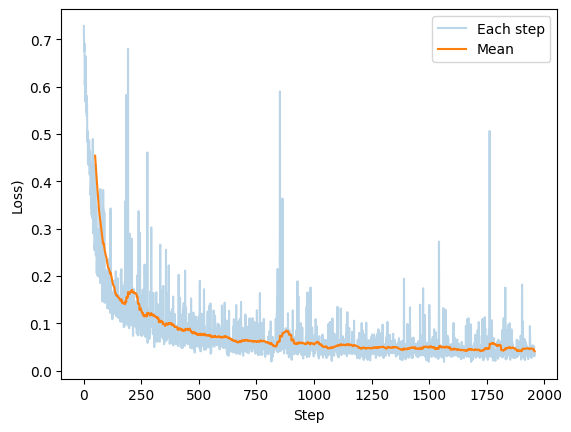

In [27]:
plt.plot(losses, alpha=0.3, label='Each step')
plt.plot(pd.Series(losses).rolling(50).mean(), label='Mean')
plt.xlabel('Step'); plt.ylabel('Loss)'); plt.legend(); plt.show()


In [28]:
torch.save(ft_model.state_dict(), f'{OUT}/segformer_b0_roadsense_train59.pt')


## Qualitative check: one test image per surface (ground truth / zero-shot B2 / fine-tuned B0)

Road pixels are shown in blue.

Loading weights:   0%|          | 0/380 [00:00<?, ?it/s]

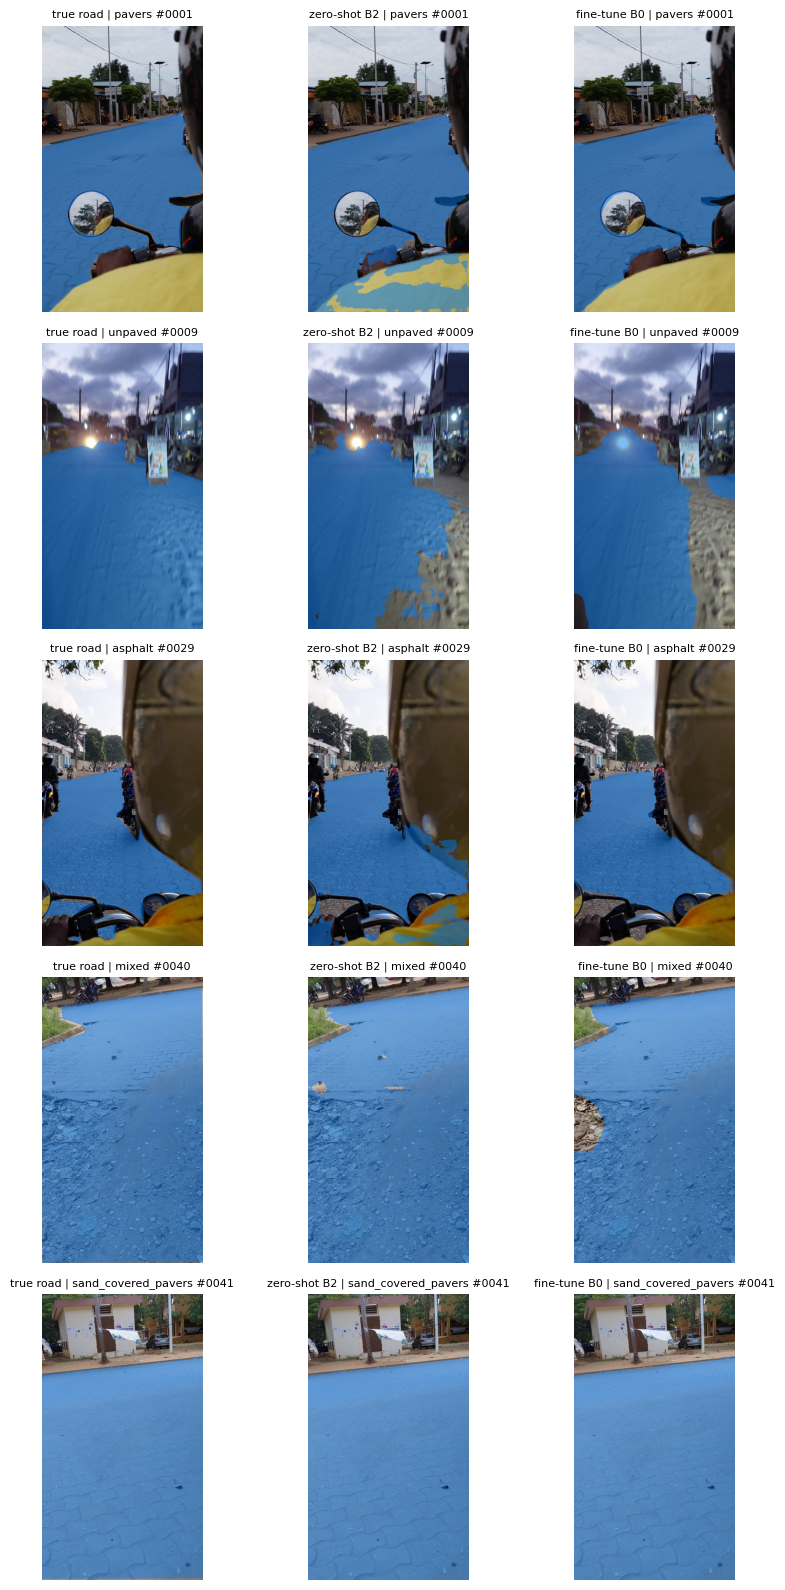

In [31]:
def predict_road(model, img, size, road_id):
    """Boolean mask: True where the model predicts road."""
    return predict_logits(model, img, size).argmax(0).cpu().numpy() == road_id

def show_road(ax, img, road, title):
    """Overlay the road pixels in blue."""
    colored = img.copy()
    colored[road] = (0.5 * colored[road] + [0, 60, 120]).astype(np.uint8)
    ax.imshow(colored)
    ax.set_title(title, fontsize=8)
    ax.axis('off')


zs = SegformerForSemanticSegmentation.from_pretrained(ZS_MODELS[1]).to(DEVICE).eval()   # zero-shot B2 Cityscapes

sample = test.groupby('surface').head(1)          # one test image per surface
fig, axes = plt.subplots(len(sample), 3, figsize=(9, 3.2 * len(sample)))

for row_axes, (_, r) in zip(axes, sample.iterrows()):
    img = load_image(r)
    truth   = load_mask(r) == 1
    road_zs = predict_road(zs,       img, ZS_SIZE,    road_id=0)   # Cityscapes: road = class 0
    road_ft = predict_road(ft_model, img, TRAIN_SIZE, road_id=1)   # fine-tuned: road = class 1

    label = f"{r['surface']} #{r['id']}"
    show_road(row_axes[0], img, truth,   f'true road | {label}')
    show_road(row_axes[1], img, road_zs, f'zero-shot B2 | {label}')
    show_road(row_axes[2], img, road_ft, f'fine-tune B0 | {label}')

plt.tight_layout()
plt.savefig(f'{OUT}/qualitative_v0.png', dpi=110)
plt.show()

del zs; torch.cuda.empty_cache()


**Observations.** On the unpaved image, both models leave out the gravel strip on the right, which our annotation counts as road; B2 leaves out more of it. On the passenger-view images, B2 labels part of the driver's yellow shirt as road; the fine-tuned model does not.

## 3. Pre-annotation of the `preannotate` split (CVAT XML)

The fine-tuned model predicts each image; the road region is turned into simplified polygons (holes such as mirrors are not kept: correct them in CVAT). One XML per CVAT task, with the **original file names** so CVAT can match them. Import in CVAT: task > Actions > Upload annotations > format `CVAT 1.1`.

In [30]:
from xml.sax.saxutils import quoteattr
pre = index[index.split == 'preannotate']
for task, df in pre.groupby('cvat_task'):
    lines = ['<?xml version="1.0" encoding="utf-8"?>', '<annotations>', '  <version>1.1</version>']
    for k, (_, r) in enumerate(df.sort_values('source_file').iterrows()):
        img = load_image(r); H, W = img.shape[:2]
        mask = predict_logits(ft_model, img, TRAIN_SIZE).argmax(0).cpu().numpy().astype(np.uint8)
        contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        lines.append(f'  <image id="{k}" name={quoteattr(r["source_file"])} width="{W}" height="{H}">')
        for c in contours:
            if cv2.contourArea(c) < 0.005 * H * W: continue          # drop tiny blobs
            c = cv2.approxPolyDP(c, 4, True).reshape(-1, 2)
            if len(c) < 3: continue
            pts = ';'.join(f'{x:.1f},{y:.1f}' for x, y in c)
            lines.append(f'    <polygon label="road" source="auto" occluded="0" points="{pts}" z_order="0"/>')
        lines.append('  </image>')
    lines.append('</annotations>')
    path = f'{OUT}/preannotations_{task}.xml'
    open(path, 'w', encoding='utf-8').write('\n'.join(lines))
    print(task, len(df), 'images ->', path)

asphalt 16 images -> /kaggle/working/preannotations_asphalt.xml
main 96 images -> /kaggle/working/preannotations_main.xml


## 4. Asphalt: dry vs rain

Rain images (wet, reflective asphalt) are kept **out of the training set on purpose**: they test a condition the fine-tuned model has never seen. Here we compare B0 before and after fine-tuning on the 13 dry and 8 rainy asphalt test images. The fine-tuned weights saved above are reloaded from disk, so this section can also be run on its own.

In [ ]:
# Weights of the fine-tuned model 

weights_file = "segformer_b0_roadsense_train59.pt"

INPUT =  Path("/kaggle/input/models/freudbokossa/segformer-fineturne/pytorch/default/1/segformer_b0_roadsense_train59.pt") 
OUT = Path("/kaggle/working")


In [33]:
# Reload the fine-tuned B0 and the zero-shot B0 for comparison
ZS_MODELS = { 'B0 Cityscapes': 'nvidia/segformer-b0-finetuned-cityscapes-1024-1024',
             'B2 Cityscapes': 'nvidia/segformer-b2-finetuned-cityscapes-1024-1024'}

ft_model = SegformerForSemanticSegmentation.from_pretrained(
    ZS_MODELS['B0 Cityscapes'], num_labels=2, ignore_mismatched_sizes=True)

ft_model.load_state_dict(torch.load(OUT / weights_file, map_location=DEVICE))
ft_model = ft_model.to(DEVICE).eval()


zs_model = SegformerForSemanticSegmentation.from_pretrained(ZS_MODELS['B0 Cityscapes']).to(DEVICE).eval()


[transformers] You passed `num_labels=2` which is incompatible to the `id2label` map of length `19`.


Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

[transformers] SegformerForSemanticSegmentation LOAD REPORT from: nvidia/segformer-b0-finetuned-cityscapes-1024-1024
Key                           | Status   |                                                                                                    
------------------------------+----------+----------------------------------------------------------------------------------------------------
decode_head.classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([19]) vs model:torch.Size([2])                      
decode_head.classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([19, 256, 1, 1]) vs model:torch.Size([2, 256, 1, 1])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


Loading weights:   0%|          | 0/208 [00:00<?, ?it/s]

In [34]:

# Split the asphalt test images by weather


asphalt = test[test.surface == 'asphalt']
dry  = asphalt[asphalt.weather == 'dry']
rain = asphalt[asphalt.weather == 'rain']

print(f'Dry Asphalt   : {len(dry)} images')
print(f'Rain Asphalt : {len(rain)} images')


Dry Asphalt   : 13 images
Rain Asphalt : 8 images


In [35]:
ZS_SIZE = (1536, 864)
TRAIN_SIZE = (768, 432)  
# Pooled road IoU (in %) of one model over a group of images

def road_iou(model, size, road_class, group):

    inter, union = 0, 0
    for _, r in group.iterrows():
        img   = load_image(r)                     
        truth = load_mask(r) == 1                 
        pred  = predict_logits(model, img, size).argmax(0).cpu().numpy() == road_class
        inter += (truth & pred).sum()
        union += (truth | pred).sum()
    return round(100 * inter / union, 1)

results = pd.DataFrame({
    'B0 zero-shot': [road_iou(zs_model, ZS_SIZE,    0, dry), road_iou(zs_model, ZS_SIZE,    0, rain)],
    'B0 fine-tune': [road_iou(ft_model, TRAIN_SIZE, 1, dry), road_iou(ft_model, TRAIN_SIZE, 1, rain)],
}, index=['Dry', 'Rain'])
results['Difference'] = results['B0 fine-tune'] - results['B0 zero-shot']
display(results)



,B0 zero-shot,B0 fine-tune,Difference
Dry,80.0,78.4,-1.6
Rain,91.8,93.0,1.2


**Observations.** After fine-tuning, B0 moves from 80.0 to 78.4 on dry asphalt and from 91.8 to 93.0 in the rain. Both changes are within run-to-run variation (an earlier run with the same recipe gave 72.3 and 94.1), so fine-tuning does not significantly change asphalt. Rain, absent from training, does not hurt the fine-tuned model.

## Summary

| Surface | Test images | B0 zero-shot | B2 zero-shot | B0 fine-tuned |
| --- | --- | --- | --- | --- |
| unpaved | 23 | 0.816 | 0.847 | **0.904** |
| asphalt | 21 | 0.847 | 0.868 | 0.845 |
| sand_covered_pavers | 10 | 0.966 | 0.971 | 0.977 |
| pavers | 8 | 0.884 | 0.844 | 0.934 |
| mixed | 1 | 0.990 | 0.988 | 0.958 |
| **All** | **63** | **0.863** | **0.880** | **0.903** |

**What we see**

- European models do not collapse on Beninese roads (pooled road IoU 0.86 to 0.88). Unpaved roads are the hardest surface.
- On unpaved roads, most missed road pixels are labelled `sidewalk`: the model sees a flat surface but does not call it road. This points to a **definition** gap rather than an appearance gap.
- 59 local images are enough for the small B0 (0.903) to beat the zero-shot B2 (0.880), a model about 6 times larger. The gain is concentrated on unpaved roads.
- Asphalt does not change significantly after fine-tuning, in dry or rainy conditions.

**Limitations**

- One training run. A previous run with the same recipe gave differences of up to 0.03 per surface (asphalt 0.813, unpaved 0.926): smaller differences are not meaningful.
- Small groups: `mixed` has 1 image, `pavers` 8. All rain images come from a single video.
- Single annotator.

**Next steps**: correct the pre-annotations and train on about 170 images; cost curve (10, 25, 50, 100+ images, 3 seeds); ImageNet vs Cityscapes initialisation; check whether fine-tuning removes the `sidewalk` confusion.